# Model I · Detention and legitimacy

The sweep varies vision (1–10), police density (1–5% of lattice sites), maximum jail term (15, 30, 60 ticks), and legitimacy feedback (0–1 by 0.2). The same three seeds are used at every setting. The risk rule rounds down the local officer-to-active ratio throughout.

Open this notebook in Colab and choose **Run all**. The first cell reads the BehaviorSpace CSV directly from GitHub. The first six lines describe the experiment. The seventh line contains the column names.

Use the plot selections below to explore the sweep. The results summarize three seeds per setting over a 180-tick window.

In [1]:
import pandas as pd

url = "https://github.com/DACSS-Complexity/s9_rebellion/raw/main/O_mexp.csv"
data = pd.read_csv(url, skiprows=6)

# Short names make the analysis easier to read.
data = data.rename(columns={
    '[run number]': 'run',
    'ticks': 'tick',
    'vision_in_patches': 'vision',
    'police-density': 'police_pct',
    'maximum-jail-term': 'max_jail',
    'legitimacy-feedback': 'feedback',
    'experiment-seed': 'seed',
    'effective-legitimacy': 'effective_legitimacy',
    'arrests-this-tick': 'arrests',
    'jailed-share': 'jailed_share',
    'count citizens with [active?]': 'active',
    'count citizens with [hidden?]': 'jailed',
})

# BehaviorSpace can interleave rows from different runs.
data = data.sort_values(['run', 'tick'])
print(f"{data['run'].nunique():,} runs, {len(data):,} tick records")

2,700 runs, 488,700 tick records


## Identify outbursts, peaks, and valleys

An episode starts when activity rises above 50 and ends when it falls below 50. Exactly 50 preserves the current episode state. The peak is the largest active count during the episode. The valley is the lowest count from the prior end to the tick before the next start. An episode still open at tick 180 has an observed peak and size but an unknown final duration.

We label runs with zero starts **no outburst**, two or more starts **recurrent**, and a single start **sustained through the window** if still open or **single completed** otherwise. A single open episode may end after the observation window. [Epstein (2002), Model I](https://pdodds.w3.uvm.edu/files/papers/others/2002/epstein2002a.pdf#page=3)

In [2]:
settings = ['vision', 'police_pct', 'max_jail', 'feedback']
keys = [*settings, 'seed']
cutoff = 50
episodes, runs = [], []
for run_id, run in data.groupby('run', sort=False):
    identifiers = {'run': run_id, **run.iloc[0][keys].to_dict()}
    episode = None
    previous_end = None
    valley = None
    starts = 0
    for tick, active in run[['tick', 'active']].itertuples(index=False, name=None):
        if episode is None and active > cutoff:
            episode = {**identifiers, 'start_tick': tick, 'peak_active': active,
                       'active_person_ticks': active, 'valley_active': valley,
                       'waiting_ticks': None if previous_end is None else tick - previous_end}
            starts += 1
        elif episode is not None:
            if active < cutoff:
                episodes.append({**episode, 'end_tick': tick,
                                 'duration_ticks': tick - episode['start_tick'], 'open_at_end': False})
                episode, previous_end, valley = None, tick, active
            else:
                episode['peak_active'] = max(episode['peak_active'], active)
                episode['active_person_ticks'] += active
        elif previous_end is not None:
            valley = min(valley, active)
    if episode is not None:
        episodes.append({**episode, 'end_tick': None, 'duration_ticks': None, 'open_at_end': True})
    pattern = ('no outburst' if starts == 0 else 'recurrent' if starts > 1
               else 'sustained through the window' if episode is not None else 'single completed')
    observed = run.iloc[1:]
    runs.append({**identifiers, 'outbursts': starts, 'pattern': pattern, 'peak_active': observed['active'].max(),
                 'mean_active': observed['active'].mean(), 'total_arrests': observed['arrests'].sum(),
                 'mean_jailed_share': observed['jailed_share'].mean(),
                 'mean_legitimacy': observed['effective_legitimacy'].mean()})

run_summary = pd.DataFrame(runs)
episode_summary = pd.DataFrame(episodes)
assert len(episode_summary) == run_summary['outbursts'].sum()
display(run_summary.groupby('feedback')['pattern'].value_counts().unstack(fill_value=0))
display(episode_summary.head(10))


pattern,no outburst,recurrent,single completed,sustained through the window
feedback,,,,
0.0,41,189,29,191
0.2,41,125,13,271
0.4,40,102,6,302
0.6,39,92,8,311
0.8,38,95,3,314
1.0,35,97,2,316


,run,vision,police_pct,max_jail,feedback,seed,start_tick,peak_active,active_person_ticks,valley_active,waiting_ticks,end_tick,duration_ticks,open_at_end
0,1,1.0,1.0,15.0,0.0,1.0,1,491,81045,NaN,NaN,NaN,NaN,True
1,2,1.0,1.0,15.0,0.2,1.0,1,506,88630,NaN,NaN,NaN,NaN,True
2,3,1.0,1.0,15.0,0.4,1.0,1,537,94694,NaN,NaN,NaN,NaN,True
3,4,1.0,1.0,15.0,0.6,1.0,1,574,99614,NaN,NaN,NaN,NaN,True
4,5,1.0,1.0,15.0,0.8,1.0,1,588,103503,NaN,NaN,NaN,NaN,True
5,6,1.0,1.0,15.0,1.0,1.0,1,624,107645,NaN,NaN,NaN,NaN,True
6,7,1.0,1.0,30.0,0.0,1.0,1,491,75144,NaN,NaN,NaN,NaN,True
7,8,1.0,1.0,30.0,0.2,1.0,1,494,86071,NaN,NaN,NaN,NaN,True
8,9,1.0,1.0,30.0,0.4,1.0,1,534,93918,NaN,NaN,NaN,NaN,True
9,10,1.0,1.0,30.0,0.6,1.0,1,569,99666,NaN,NaN,NaN,NaN,True


## Compare with the matched fixed-legitimacy baseline

For every positive feedback value, subtract the result at λ = 0 for the same vision, density, maximum jail term, and seed. The plotted counts and differences are averages across the three seeds. Pick a density and jail term to compare all vision settings and feedback levels.

,outbursts,mean_active,total_arrests,mean_jailed_share,mean_legitimacy
feedback,,,,,
0.0,3.509,128.894,3210.160,0.224,0.820
0.2,2.629,195.678,4349.378,0.311,0.758
0.4,2.411,248.092,5010.469,0.363,0.675
0.6,2.198,283.476,5293.260,0.387,0.588
0.8,2.198,311.180,5518.891,0.405,0.496
1.0,2.053,330.224,5663.527,0.419,0.402


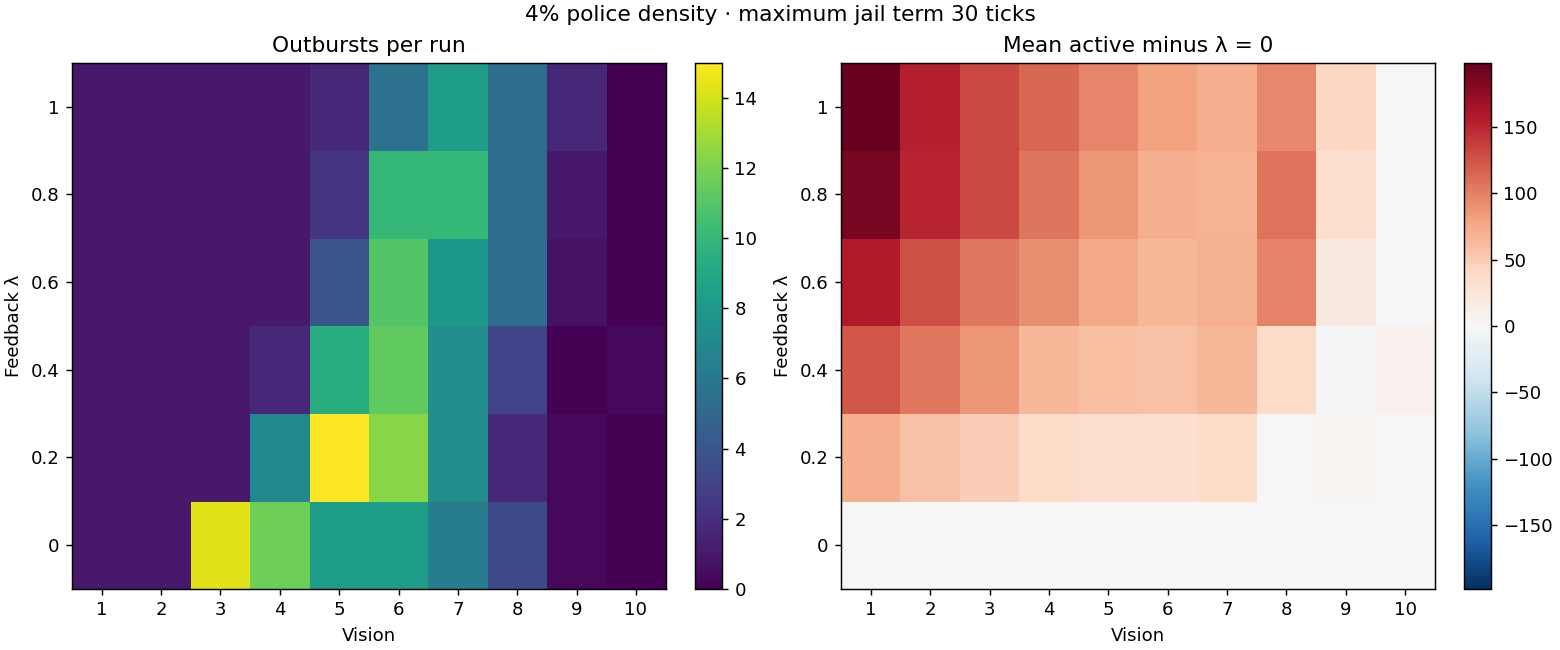

outbursts  mean_active  total_arrests  mean_jailed_share  mean_legitimacy  delta_mean_active
vision feedback                                                                                              
1.0    0.0           1.000      236.320       2913.667              0.212            0.820              0.000
       0.2           1.000      307.843       3721.333              0.271            0.766             71.522
       0.4           1.000      359.500       4537.333              0.332            0.687            123.180
       0.6           1.000      394.007       5140.333              0.378            0.593            157.687
       0.8           1.000      424.724       5395.333              0.389            0.509            188.404
       1.0           1.000      434.252       5702.000              0.418            0.402            197.931
2.0    0.0           1.000      127.222       4049.000              0.297            0.820              0.000
       0.2           1.000      185.533       5806.000              0.422            0.736             58.311
       0.4           1.000      231.806       6835.667              0.498            0.621            104.583
       0.6           1.000      253.333       7432.333              0.544            0.494            126.111
       0.8           1.000      278.304       7739.667              0.563            0.369            151.081
       1.0           1.000      280.400       8070.667              0.591            0.229            153.178
3.0    0.0          14.333       65.387       4588.000              0.333            0.820              0.000
       0.2           1.000      114.548       6705.000              0.491            0.722             49.161
       0.4           1.000      152.169       7940.333              0.581            0.588             86.781
       0.6           1.000      169.406       8645.000              0.630            0.442            104.019
       0.8           1.000      196.446       8848.000              0.645            0.304            131.059
       1.0           1.000      195.624       9222.667              0.673            0.147            130.237

In [3]:
import numpy as np
import matplotlib.pyplot as plt

matched_on = ['vision', 'police_pct', 'max_jail', 'seed']
outcomes = ['outbursts', 'mean_active', 'total_arrests', 'mean_jailed_share', 'mean_legitimacy']
baseline = run_summary.loc[run_summary['feedback'].eq(0), [*matched_on, *outcomes]]
paired = run_summary.merge(baseline, on=matched_on, suffixes=('', '_baseline'), validate='many_to_one')
for outcome in outcomes:
    paired[f'delta_{outcome}'] = paired[outcome] - paired[f'{outcome}_baseline']

display(paired.groupby('feedback')[outcomes].mean().round(3))

police_pct = 4
max_jail = 30
selected = paired.query('police_pct == @police_pct and max_jail == @max_jail')
fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout='constrained')
for ax, metric, label, cmap in zip(
    axes, ['outbursts', 'delta_mean_active'],
    ['Outbursts per run', 'Mean active minus λ = 0'], ['viridis', 'RdBu_r']
):
    grid = selected.pivot_table(index='feedback', columns='vision', values=metric)
    if metric.startswith('delta'):
        bound = max(1, np.abs(grid.to_numpy()).max())
        image = ax.imshow(grid, origin='lower', aspect='auto', cmap=cmap, vmin=-bound, vmax=bound)
    else:
        image = ax.imshow(grid, origin='lower', aspect='auto', cmap=cmap)
    ax.set(xticks=range(len(grid.columns)), xticklabels=[f'{v:g}' for v in grid.columns],
           yticks=range(len(grid.index)), yticklabels=[f'{v:g}' for v in grid.index],
           xlabel='Vision', ylabel='Feedback λ', title=label)
    fig.colorbar(image, ax=ax)
fig.suptitle(f'{police_pct}% police density · maximum jail term {max_jail} ticks')
plt.show()

display(selected.groupby(['vision', 'feedback'])[[*outcomes, 'delta_mean_active']].mean().round(3).head(18))


## Compare jail terms at fixed vision and police density

Each line varies the maximum jail term at a particular feedback strength. Use the run table to interpret changes in outburst frequency alongside changes in average activity and the jailed share.

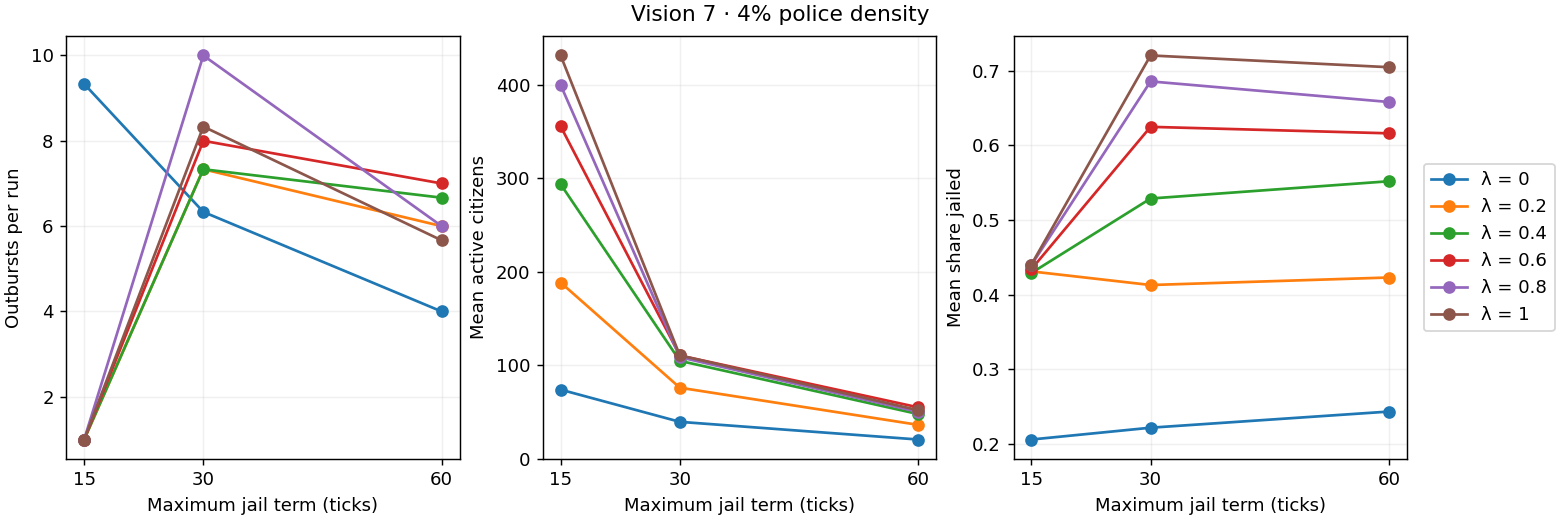

In [4]:
comparison_vision = 7
jail_comparison = paired.query('vision == @comparison_vision and police_pct == @police_pct')
by_term = jail_comparison.groupby(['feedback', 'max_jail'])[
    ['outbursts', 'mean_active', 'mean_jailed_share']
].mean().reset_index()
fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout='constrained')
for feedback, group in by_term.groupby('feedback'):
    for ax, metric in zip(axes, ['outbursts', 'mean_active', 'mean_jailed_share']):
        ax.plot(group['max_jail'], group[metric], marker='o', label=f'λ = {feedback:g}')
for ax, label in zip(axes, ['Outbursts per run', 'Mean active citizens', 'Mean share jailed']):
    ax.set(xlabel='Maximum jail term (ticks)', ylabel=label, xticks=[15, 30, 60])
    ax.grid(alpha=.18)
axes[-1].legend(loc='center left', bbox_to_anchor=(1.02, .5))
fig.suptitle(f'Vision {comparison_vision} · {police_pct}% police density')
plt.show()


## Inspect paired trajectories

The active count shows when outbursts occur. The jailed count and effective legitimacy show the state that feeds into the next tick. Change the selected seed or vision to inspect another pair.

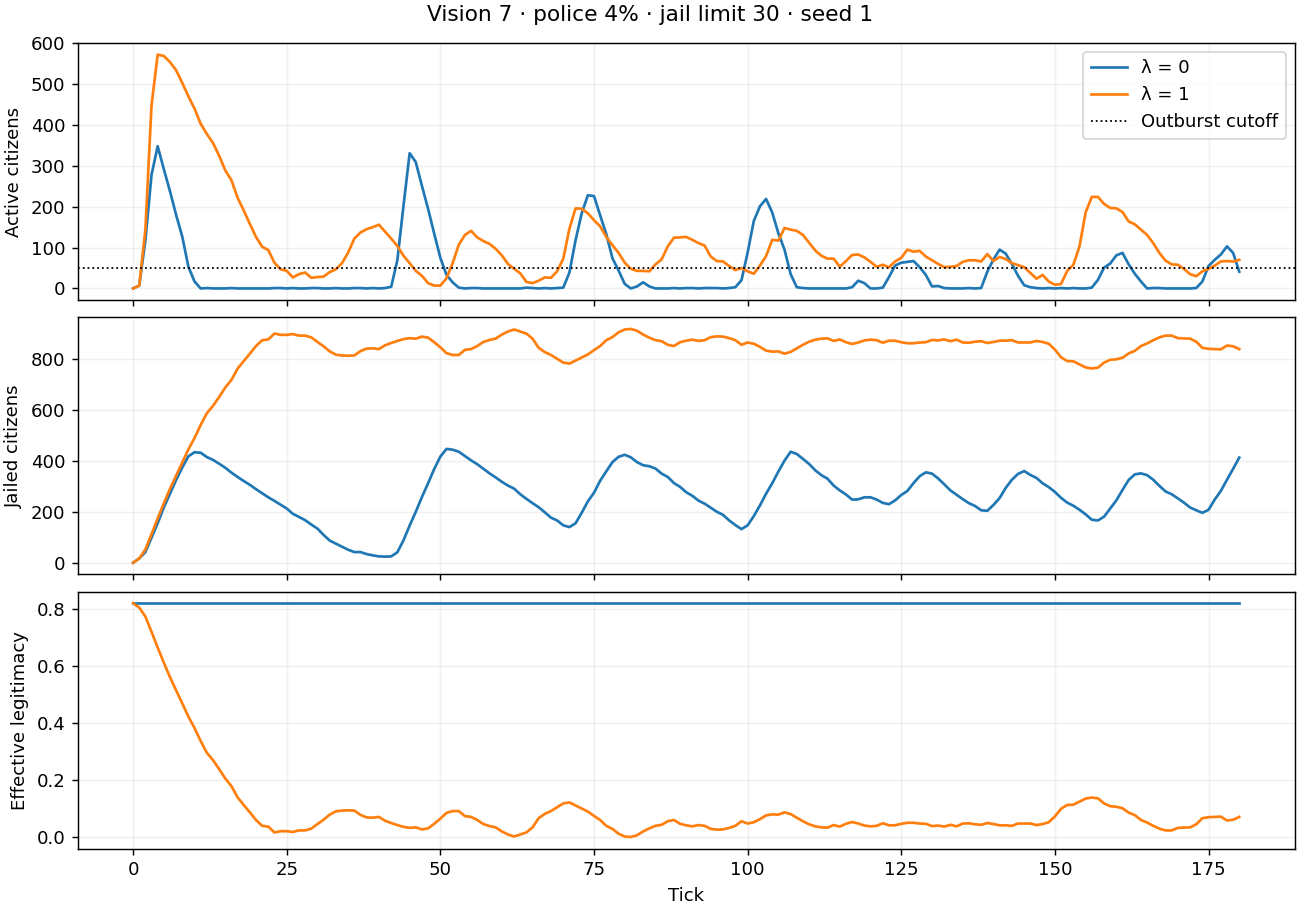

In [5]:
vision, seed = 7, 1
paths = data.query('vision == @vision and seed == @seed and police_pct == @police_pct and max_jail == @max_jail and feedback in [0, 1]')
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True, layout='constrained')
for feedback, group in paths.groupby('feedback'):
    for ax, metric in zip(axes, ['active', 'jailed', 'effective_legitimacy']):
        ax.plot(group['tick'], group[metric], label=f'λ = {feedback:g}')
axes[0].axhline(cutoff, color='black', ls=':', linewidth=1, label='Outburst cutoff')
for ax, label in zip(axes, ['Active citizens', 'Jailed citizens', 'Effective legitimacy']):
    ax.set_ylabel(label)
    ax.grid(alpha=.18)
axes[0].legend()
axes[-1].set_xlabel('Tick')
fig.suptitle(f'Vision {vision} · police {police_pct}% · jail limit {max_jail} · seed {seed}')
plt.show()
